In [2]:
%pip install wget
%pip install pandas
%pip install seaborn

Note: you may need to restart the kernel to use updated packages.
Note: you may need to restart the kernel to use updated packages.
Note: you may need to restart the kernel to use updated packages.


In [3]:
#Apertura de los archivos
import pandas as pd
from os import path, listdir
df_calendar=pd.read_csv("calendar.csv.gz")
df_listings = pd.read_csv("listings (1).csv.gz")

# chequeamos si los archivos están en el directorio donde estamos parados
lista_archivos = listdir("./")
print(f"El contenido de la carpeta es: {lista_archivos}")

El contenido de la carpeta es: ['.git', '.gitignore', 'Azucar', 'calendar.csv.gz', 'entrega.ipynb', 'Entregaf.ipynb', 'HipotesisCande.ipynb', 'listings (1).csv.gz', 'prueba1.ipynb', 'prueba2.ipynb', 'prueba3.ipynb', 'prueba4.ipynb', 'pruebanub.ipynb', 'pruebanubultimaver.ipynb', 'README.md', 'requirements.txt', 'tabla_cruzada.png', 'TPE_CienciaDeDatos']


In [4]:
df_calendar.info()
df_listings.info()

<class 'pandas.DataFrame'>
RangeIndex: 10835026 entries, 0 to 10835025
Data columns (total 5 columns):
 #   Column          Dtype
---  ------          -----
 0   listing_id      int64
 1   date            str  
 2   available       str  
 3   minimum_nights  int64
 4   maximum_nights  int64
dtypes: int64(3), str(2)
memory usage: 413.3 MB
<class 'pandas.DataFrame'>
RangeIndex: 29685 entries, 0 to 29684
Data columns (total 90 columns):
 #   Column                                        Non-Null Count  Dtype  
---  ------                                        --------------  -----  
 0   id                                            29685 non-null  int64  
 1   listing_url                                   29685 non-null  str    
 2   scrape_id                                     29685 non-null  int64  
 3   last_scraped                                  29685 non-null  str    
 4   source                                        29685 non-null  str    
 5   name                            

In [5]:
df_listings.head()
df_calendar.head()

,listing_id,date,available,minimum_nights,maximum_nights
0,11508,2026-06-30,f,3,1125
1,11508,2026-07-01,f,3,1125
2,11508,2026-07-02,f,3,1125
3,11508,2026-07-03,f,3,1125
4,11508,2026-07-04,f,3,1125


In [6]:
df_listings['beds'].describe()

count    27102.000000
mean         1.947753
std          1.621595
min          1.000000
25%          1.000000
50%          1.000000
75%          2.000000
max         50.000000
Name: beds, dtype: float64

In [7]:
df_listings["price"].value_counts()

price
$101,250.00    59
$118,985.00    51
$76,496.00     38
$93,491.50     38
$84,993.50     37
               ..
$28,874.01      1
$34,495.44      1
$69,170.33      1
$43,180.33      1
$92,576.33      1
Name: count, Length: 19349, dtype: int64

implementación de operaciones de limpieza de la base

In [8]:
import numpy as np

#copiamos el conjunto para preservarlo
preprocessed_dataset = df_listings.copy()
#Eliminamos columanas con valores nulos, links, imagenes o ids que no eran utiles para nuestro analisis
preprocessed_dataset = preprocessed_dataset.drop('neighborhood_overview', axis=1)
preprocessed_dataset = preprocessed_dataset.drop('host_since', axis=1)
preprocessed_dataset = preprocessed_dataset.drop('host_response_time', axis=1)
preprocessed_dataset = preprocessed_dataset.drop('host_response_rate', axis=1)
preprocessed_dataset = preprocessed_dataset.drop('host_acceptance_rate', axis=1)
preprocessed_dataset = preprocessed_dataset.drop('host_thumbnail_url', axis=1)
preprocessed_dataset = preprocessed_dataset.drop('host_neighbourhood', axis=1)
preprocessed_dataset = preprocessed_dataset.drop('host_total_listings_count', axis=1)
preprocessed_dataset = preprocessed_dataset.drop('host_verifications', axis=1)
preprocessed_dataset = preprocessed_dataset.drop('neighbourhood', axis=1)
preprocessed_dataset = preprocessed_dataset.drop('neighbourhood_group_cleansed', axis=1)
preprocessed_dataset = preprocessed_dataset.drop('calendar_updated', axis=1)
preprocessed_dataset = preprocessed_dataset.drop('instant_bookable', axis=1)
preprocessed_dataset = preprocessed_dataset.drop('listing_url',axis=1)
preprocessed_dataset = preprocessed_dataset.drop('host_url',axis=1)
preprocessed_dataset = preprocessed_dataset.drop('host_profile_id',axis=1)
preprocessed_dataset = preprocessed_dataset.drop('host_profile_url',axis=1)
preprocessed_dataset = preprocessed_dataset.drop('host_name',axis=1)
preprocessed_dataset = preprocessed_dataset.drop('scrape_id',axis=1)
preprocessed_dataset = preprocessed_dataset.drop('picture_url',axis=1)
preprocessed_dataset = preprocessed_dataset.drop('license',axis=1)
preprocessed_dataset = preprocessed_dataset.drop('host_picture_url',axis=1)
preprocessed_dataset = preprocessed_dataset.drop('host_about',axis=1)

#transformacion de variables a dicotomicas
preprocessed_dataset ['source']= preprocessed_dataset['source'].map({"city scrape": True, "previous scrape": False})
preprocessed_dataset ['has_availability']= preprocessed_dataset['has_availability'].map({"t": True, "f": False}).fillna(False).astype(bool)
preprocessed_dataset ['host_is_superhost']= preprocessed_dataset['host_is_superhost'].map({"t": True, "f": False})
preprocessed_dataset ['host_has_profile_pic']= preprocessed_dataset['host_has_profile_pic'].map({"t": True, "f": False})
preprocessed_dataset ['host_identity_verified']= preprocessed_dataset['host_identity_verified'].map({"t": True, "f": False})

#transformacion de price a una variable de tipo float
preprocessed_dataset['price'] = preprocessed_dataset['price'].str.replace(r'[$,]', '', regex=True).astype(float)

In [9]:

#Queremos ver el tipo de alojamiento al que pertenece y vamos a imputar por la mediana de los precios de ese tipo de alojamiento para no tener nulos y evitar eliminar filas

# Cantidad y porcentaje de nulos
print(preprocessed_dataset["price"].isna().sum())
print(preprocessed_dataset["price"].isna().mean() * 100)
nulos = preprocessed_dataset[preprocessed_dataset["price"].isna()]

# Nulos por tipo de alojamiento
print(preprocessed_dataset.groupby("room_type")["price"].apply(lambda s: s.isna().sum()))
preprocessed_dataset["price"] = preprocessed_dataset["price"].fillna(
    preprocessed_dataset.groupby("room_type")["price"].transform("median")
)

preprocessed_dataset["price"].info()

1792
6.036718881590029
room_type
Entire home/apt    1649
Hotel room            5
Private room        131
Shared room           7
Name: price, dtype: int64
<class 'pandas.Series'>
RangeIndex: 29685 entries, 0 to 29684
Series name: price
Non-Null Count  Dtype  
--------------  -----  
29685 non-null  float64
dtypes: float64(1)
memory usage: 232.0 KB


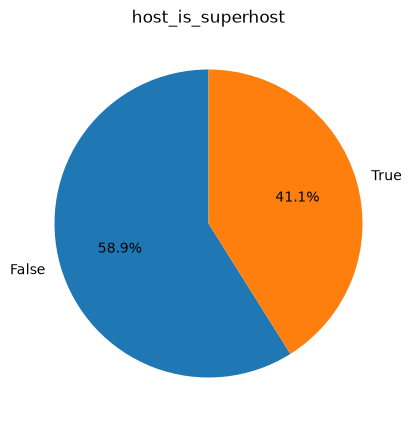

In [10]:
import matplotlib.pyplot as plt
import pandas as pd
frec=preprocessed_dataset["host_is_superhost"].value_counts()
plt.figure(figsize=(5, 5))
frec.plot(kind="pie", autopct="%1.1f%%", startangle=90)
plt.ylabel("")
plt.title("host_is_superhost")
plt.show()

In [11]:
preprocessed_dataset['accommodates'].value_counts()

accommodates
2     14374
4      6001
3      5183
1      1419
5      1110
6       919
8       223
7       159
16       79
10       76
9        51
12       35
11       19
15       17
14       15
13        5
Name: count, dtype: int64

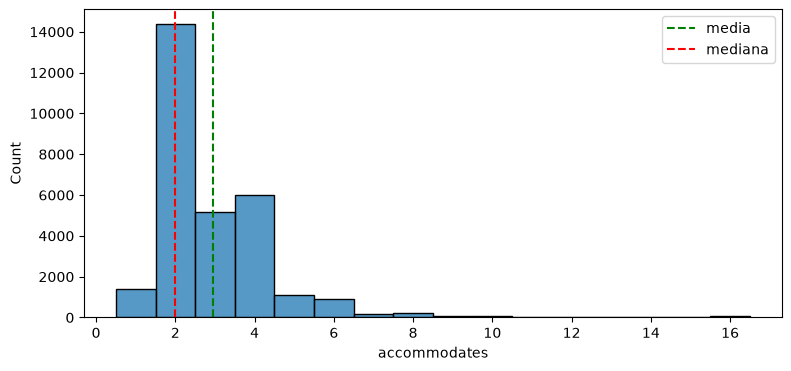

In [12]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
acc = preprocessed_dataset["accommodates"].dropna()

plt.figure(figsize=(9, 4))
sns.histplot(acc, discrete=True)
plt.axvline(acc.mean(), color="green", linestyle="--", label="media")
plt.axvline(acc.median(), color="red", linestyle="--", label="mediana")
plt.legend()
plt.show()

Nulos: 0
Categorías: 4
Moda: Entire home/apt
                 Frecuencia  Porcentaje
room_type                              
Entire home/apt       26790       90.25
Private room           2616        8.81
Hotel room              141        0.47
Shared room             138        0.46


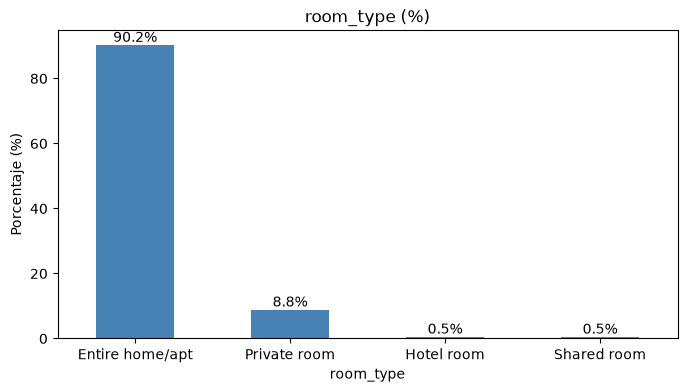

In [13]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

rt = preprocessed_dataset["room_type"]

print("Nulos:", rt.isna().sum())
print("Categorías:", rt.nunique())
print("Moda:", rt.mode().iloc[0])

frec = rt.value_counts()
prop = rt.value_counts(normalize=True) * 100

tabla = pd.DataFrame({"Frecuencia": frec, "Porcentaje": prop.round(2)})
print(tabla)

orden = rt.value_counts().index
plt.figure(figsize=(8, 4))
ax = prop.plot(kind="bar", color="steelblue")
ax.bar_label(ax.containers[0], fmt="%.1f%%")
plt.ylabel("Porcentaje (%)")
plt.xticks(rotation=0)
plt.title("room_type (%)")
plt.show()

In [14]:

print(preprocessed_dataset['price'].describe())

#tenemos muchos outliers un minimo muy bajo y un maximo muy grande
#para definir la hipotesis, podemos filtrar? eliminamos outliers? planteamos la hipotesis con datos externos la media o la mediana?
#imputar por la mediana de oublicaciones del mismo tipo

count    2.968500e+04
mean     2.652253e+05
std      3.511514e+06
min      1.215500e+03
25%      7.627600e+04
50%      1.035040e+05
75%      1.365218e+05
max      1.716438e+08
Name: price, dtype: float64


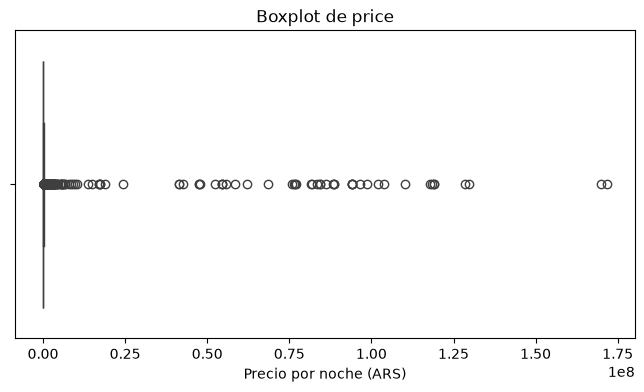

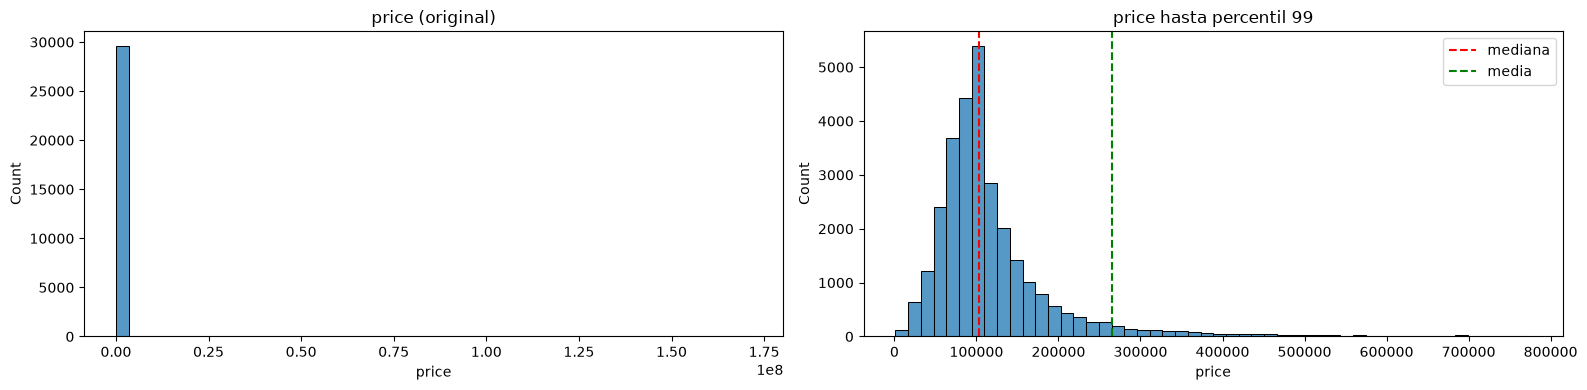

In [15]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8, 4))
sns.boxplot(x=preprocessed_dataset["price"])
plt.title("Boxplot de price")
plt.xlabel("Precio por noche (ARS)")
plt.show()

precio = preprocessed_dataset["price"]

fig, ax = plt.subplots(1, 2, figsize=(16, 4))

# a) Original
sns.histplot(precio, bins=50, ax=ax[0])
ax[0].set_title("price (original)")

# b) Recortado al percentil 99
p99 = precio.quantile(0.99)
sns.histplot(precio[precio <= p99], bins=50, ax=ax[1])
ax[1].axvline(precio.median(), color="red", linestyle="--", label="mediana")
ax[1].axvline(precio.mean(), color="green", linestyle="--", label="media")
ax[1].legend()
ax[1].set_title("price hasta percentil 99")

plt.tight_layout()
plt.show()
#En el siguiente boxpot podemos ver que es un varibale con una gran cantidad de outliers, entonces vamos a intentar filtrar nuestros datos para que el analisis tenga mas valor,
#obviamente comparar el precio de una habitacion compartida con una mansion no tiene mucho sentido, apunta a gente diferente

Nuestro analisis lo vamos a hacer sobre alojamientos de hasta dos personas, ya que la gran mayoria ofrece para esa cantidad y creemos que es un buen analisis

n: 15793
count    1.579300e+04
mean     2.492372e+05
std      3.753501e+06
min      1.215500e+03
1%       2.024672e+04
5%       3.430670e+04
25%      6.553992e+04
50%      8.774900e+04
75%      1.096940e+05
90%      1.486528e+05
95%      1.930351e+05
99%      4.535363e+05
max      1.716438e+08
Name: price, dtype: float64


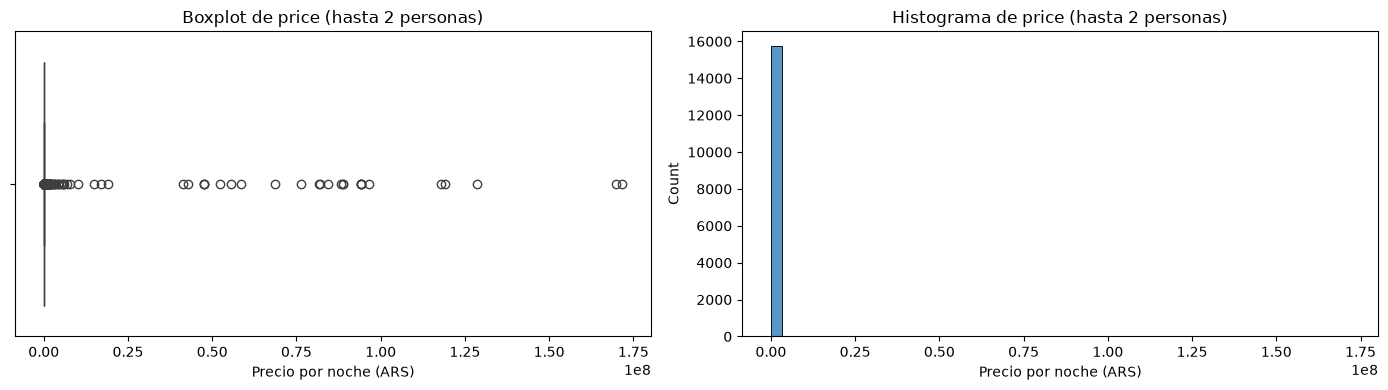

In [16]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
grupo = preprocessed_dataset[preprocessed_dataset["accommodates"] <= 2].copy()
precio = grupo["price"]

print("n:", len(grupo))
print(precio.describe(percentiles=[.01, .05, .25, .5, .75, .90, .95, .99]))
fig, ax = plt.subplots(1, 2, figsize=(14, 4))

sns.boxplot(x=precio, ax=ax[0])
ax[0].set_title("Boxplot de price (hasta 2 personas)")
ax[0].set_xlabel("Precio por noche (ARS)")

sns.histplot(precio, bins=50, ax=ax[1])
ax[1].set_title("Histograma de price (hasta 2 personas)")
ax[1].set_xlabel("Precio por noche (ARS)")

plt.tight_layout()
plt.show()
#podemos ver que seguimos teniendo outliers

In [17]:
#Limpiamos outliers, nos quedamos con las muestras que se distribuyen dentro los bigotes del boxplot
#Estamos quedandonos con los datos que se distribuyen dentro de los bigotes, de esta manera evitamos outliers, que vemos que representan el 6.24%, esta decision la tomamos xq queremos compara comparar
# alojamientos dentro del mismo rango de precios, entonces consideramos que tener en cuenta los datos que se distribuyen dentro del box plot con 4 cuartiles es una buena forma
precio = grupo["price"]

q1 = precio.quantile(0.25)
q3 = precio.quantile(0.75)
iqr = q3 - q1

lim_sup = q3 + 1.5 * iqr

grupo_limpio = grupo[grupo["price"] <= lim_sup].copy()

print("Límite superior (Q3 + 1,5·IQR):", lim_sup)
print("Bigote máximo (mayor precio que queda):", grupo_limpio["price"].max())
print("Registros antes:", len(grupo))
print("Registros después:", len(grupo_limpio))
print("Eliminados:", len(grupo) - len(grupo_limpio),
      f"({(1 - len(grupo_limpio) / len(grupo)) * 100:.2f}%)")

Límite superior (Q3 + 1,5·IQR): 175925.12
Bigote máximo (mayor precio que queda): 175772.46
Registros antes: 15793
Registros después: 14807
Eliminados: 986 (6.24%)


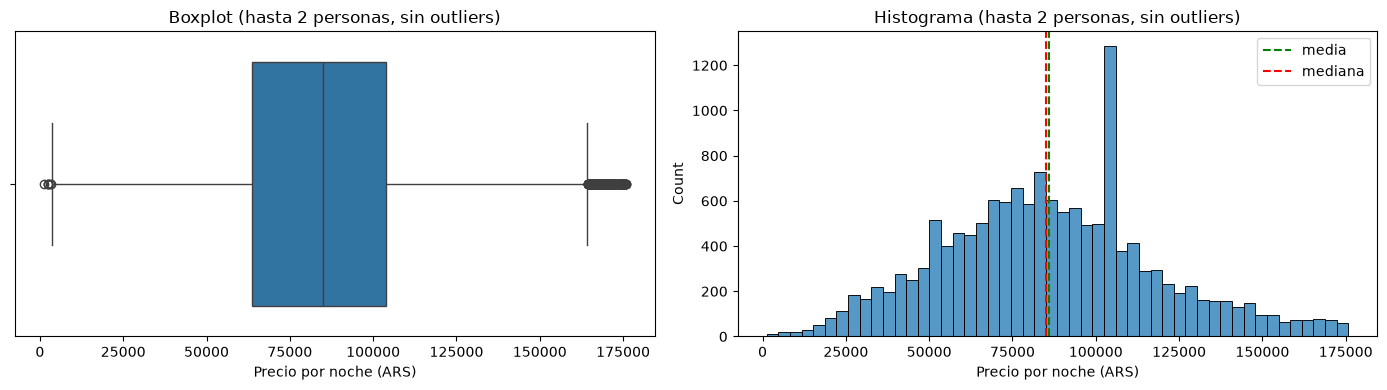

count     14807.000000
mean      86024.882618
std       32290.103616
min        1215.500000
1%        19508.482000
5%        33983.113000
25%       63736.350000
50%       84993.670000
75%      103977.000000
95%      144486.000000
99%      168318.967000
max      175772.460000
Name: price, dtype: float64


In [18]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4))

sns.boxplot(x=grupo_limpio["price"], ax=ax[0])
ax[0].set_title("Boxplot (hasta 2 personas, sin outliers)")
ax[0].set_xlabel("Precio por noche (ARS)")

sns.histplot(grupo_limpio["price"], bins=50, ax=ax[1])
ax[1].axvline(grupo_limpio["price"].mean(), color="green", linestyle="--", label="media")
ax[1].axvline(grupo_limpio["price"].median(), color="red", linestyle="--", label="mediana")
ax[1].legend()
ax[1].set_title("Histograma (hasta 2 personas, sin outliers)")
ax[1].set_xlabel("Precio por noche (ARS)")

plt.tight_layout()
plt.show()

print(grupo_limpio["price"].describe(percentiles=[.01, .05, .25, .5, .75, .95, .99]))

In [19]:
# Test de Shapiro-Wilk para price
from scipy.stats import shapiro

precio= grupo_limpio["price"]
stat, p = shapiro(precio)
print(f"Test de Shapiro-Wilk, precio de alquileres por noche: Estadístico={stat:.3f}, p-valor={p:.3f}")

Test de Shapiro-Wilk, precio de alquileres por noche: Estadístico=0.992, p-valor=0.000


d:\Proyectos\Trabajo Fundamentos\TPE_CienciaDeDatos\Azucar\Lib\site-packages\scipy\stats\_axis_nan_policy.py:601: UserWarning: scipy.stats.shapiro: For N > 5000, computed p-value may not be accurate. Current N is 14807.
  res = hypotest_fun_out(*samples, **kwds)


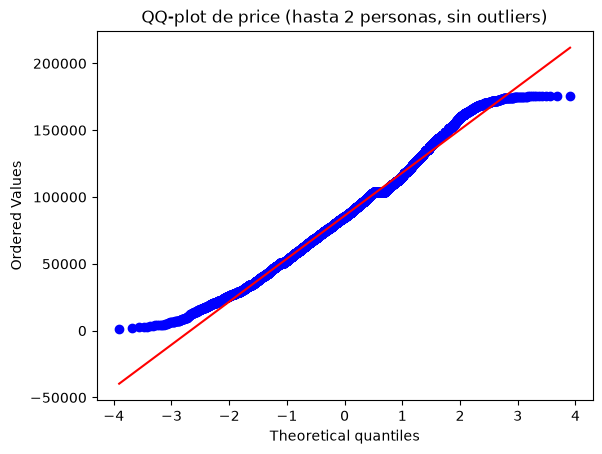

In [20]:
import scipy.stats as st
import matplotlib.pyplot as plt

st.probplot(grupo_limpio["price"], dist="norm", plot=plt)
plt.title("QQ-plot de price (hasta 2 personas, sin outliers)")
plt.show()


Analisis de la hipotesis Airbnb en Bs. As. es un negocio de grandes jugadores: más del 60% de la oferta la controlan agencias multipropiedad, no personas alquilando su propio
hogar

count    14556.000000
mean         2.039365
std          5.179714
min          1.000000
25%          1.000000
50%          1.000000
75%          2.000000
max        208.000000
Name: calculated_host_listings_count, dtype: float64
calculated_host_listings_count
1     10808
2      1878
3       647
4       336
5       192
6       121
7       102
8        67
9        57
10       43
Name: count, dtype: int64


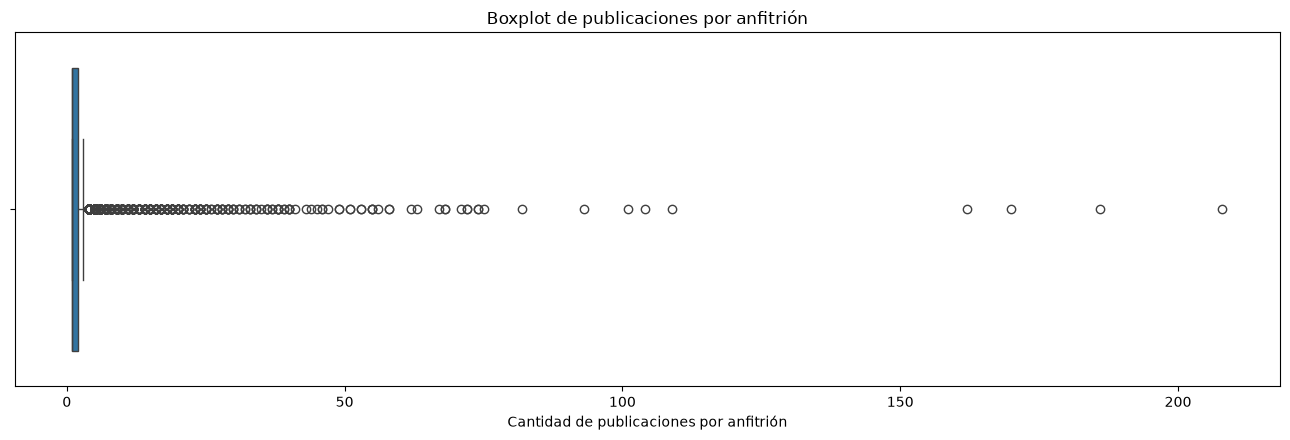

In [21]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

c_t = 'calculated_host_listings_count'
hosts = preprocessed_dataset.drop_duplicates('host_id')   # una fila por anfitrión

print(hosts[c_t].describe())
print(hosts[c_t].value_counts().sort_index().head(10))

fig, ax = plt.subplots(figsize=(13, 4.5))

sns.boxplot(x=hosts[c_t], ax=ax)
ax.set_title('Boxplot de publicaciones por anfitrión')
ax.set_xlabel('Cantidad de publicaciones por anfitrión')

plt.tight_layout()
plt.show()

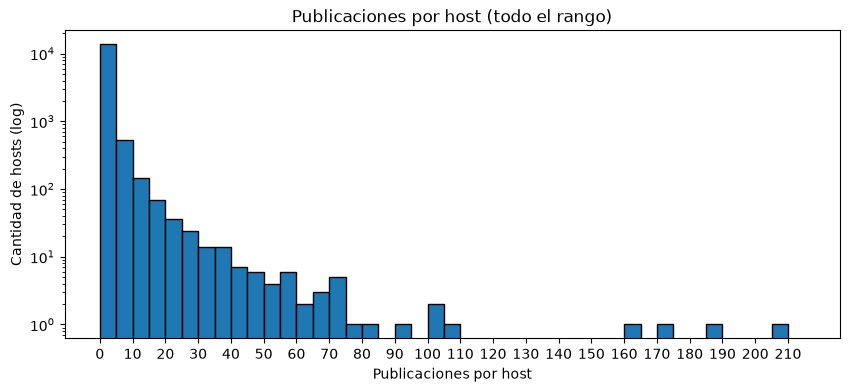

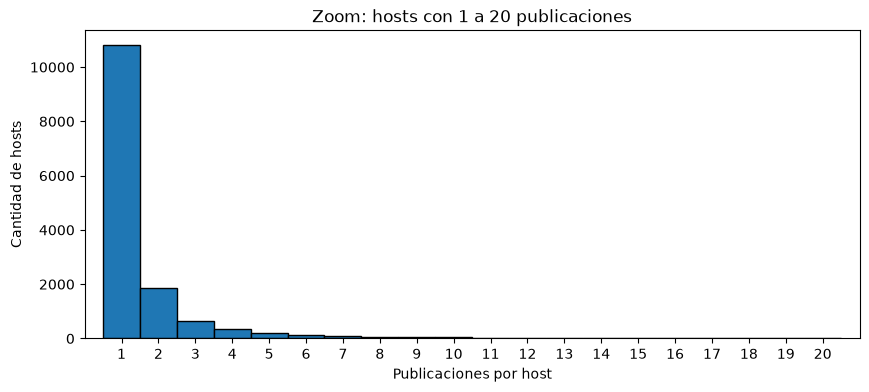

In [22]:
import numpy as np
import matplotlib.pyplot as plt

col = "calculated_host_listings_count"
hosts = preprocessed_dataset.drop_duplicates('host_id')

plt.figure(figsize=(10, 4))
plt.hist(hosts[col], bins=np.arange(0, 220, 5), edgecolor='black')
plt.xticks(np.arange(0, 220, 10))
plt.yscale('log')
plt.xlabel("Publicaciones por host")
plt.ylabel("Cantidad de hosts (log)")
plt.title("Publicaciones por host (todo el rango)")
plt.show()

plt.figure(figsize=(10, 4))
plt.hist(hosts[col], bins=np.arange(0.5, 21.5, 1), edgecolor='black')  # una barra por valor entero
plt.xticks(np.arange(1, 21, 1))
plt.xlim(0, 21)
plt.xlabel("Publicaciones por host")
plt.ylabel("Cantidad de hosts")
plt.title("Zoom: hosts con 1 a 20 publicaciones")
plt.show()


count    14556.000000
mean         2.039365
std          5.179714
min          1.000000
25%          1.000000
50%          1.000000
75%          2.000000
max        208.000000
Name: calculated_host_listings_count, dtype: float64
calculated_host_listings_count
1     10808
2      1878
3       647
4       336
5       192
6       121
7       102
8        67
9        57
10       43
Name: count, dtype: int64


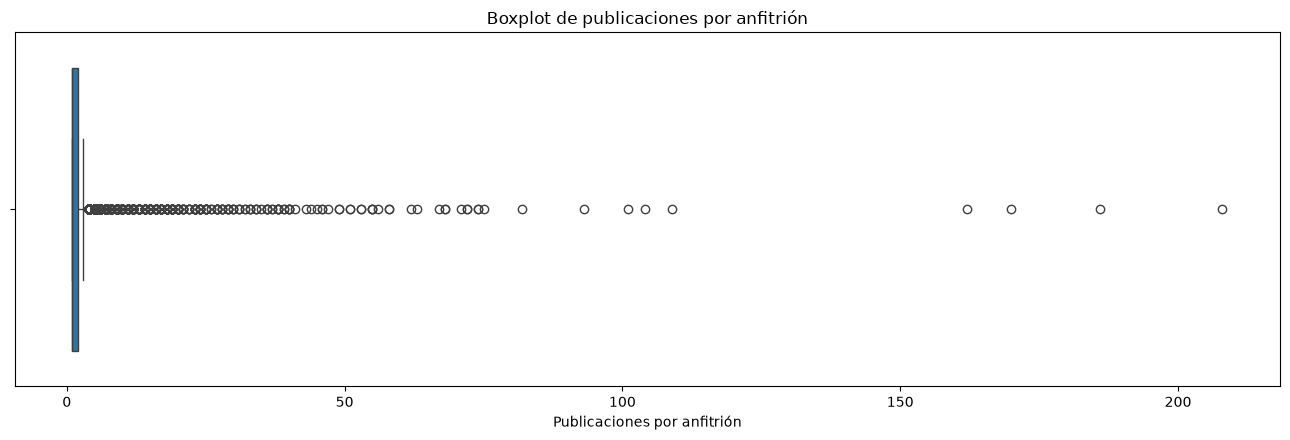

In [23]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

c_t = 'calculated_host_listings_count'
hosts = preprocessed_dataset.drop_duplicates('host_id')   # una fila por anfitrión

# Resumen numérico primero
print(hosts[c_t].describe())
print(hosts[c_t].value_counts().sort_index().head(10))

fig, ax = plt.subplots(figsize=(13, 4.5))

sns.boxplot(x=hosts[c_t], ax=ax)
ax.set_title('Boxplot de publicaciones por anfitrión')
ax.set_xlabel('Publicaciones por anfitrión')

plt.tight_layout()
plt.show()

In [24]:
import pandas as pd

col = "calculated_host_listings_count_entire_homes"

# Solo alojamientos enteros
ent = preprocessed_dataset[preprocessed_dataset["room_type"] == "Entire home/apt"].copy()

print("Entire home/apt:", len(ent), f"({len(ent)/len(preprocessed_dataset)*100:.1f}%)")

#Filtramos a los que tienen dos o mas propiedades
ent["multi"] = ent[col] >= 2

#Hasta aca creamos una nueva columna que nos permitio identificar a las agencias multipropiedad, en este caso consideramos que tener mas de dos propiedades enteras es multipropiedad

Entire home/apt: 26790 (90.2%)


count    26790.000000
mean        15.614707
std         34.013510
min          1.000000
25%          1.000000
50%          2.000000
75%         12.000000
90%         43.000000
95%         72.000000
99%        186.000000
max        208.000000
Name: calculated_host_listings_count_entire_homes, dtype: float64
Moda: 1
Asimetría: 3.726271433659678


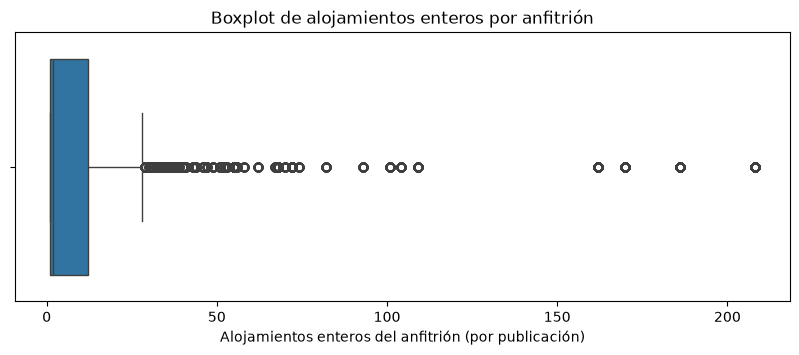

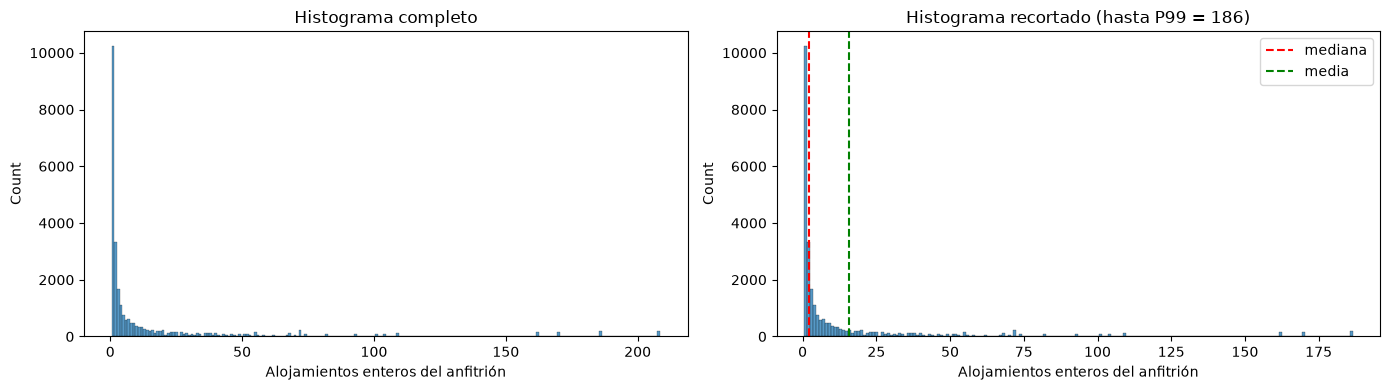

In [25]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

col = "calculated_host_listings_count_entire_homes"
v = ent[col]

print(v.describe(percentiles=[.25, .5, .75, .90, .95, .99]))
print("Moda:", v.mode().iloc[0])
print("Asimetría:", v.skew())

plt.figure(figsize=(10, 3.5))
sns.boxplot(x=v)
plt.title("Boxplot de alojamientos enteros por anfitrión")
plt.xlabel("Alojamientos enteros del anfitrión (por publicación)")
plt.show()


p99 = v.quantile(0.99)

fig, axes = plt.subplots(1, 2, figsize=(14, 4))

sns.histplot(v, discrete=True, ax=axes[0])
axes[0].set_title("Histograma completo")
axes[0].set_xlabel("Alojamientos enteros del anfitrión")

sns.histplot(v[v <= p99], discrete=True, ax=axes[1])
axes[1].axvline(v.median(), color="red", linestyle="--", label="mediana")
axes[1].axvline(v.mean(), color="green", linestyle="--", label="media")
axes[1].legend()
axes[1].set_title(f"Histograma recortado (hasta P99 = {p99:.0f})")
axes[1].set_xlabel("Alojamientos enteros del anfitrión")

plt.tight_layout()
plt.show()

bin
1           38.2
2           12.4
3 a 4       10.3
5 a 9       10.8
10 o más    28.3
Name: proportion, dtype: float64


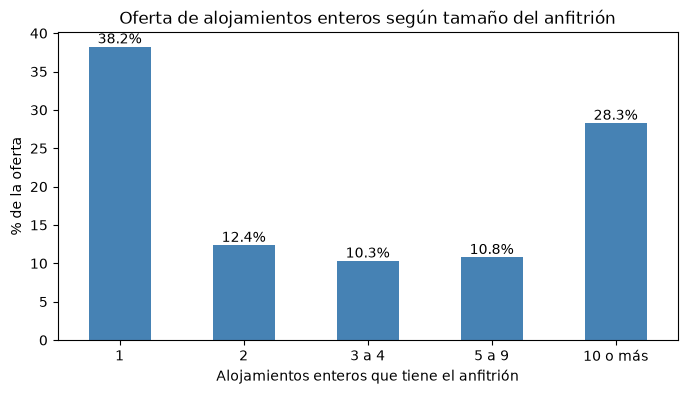

In [26]:
ent["bin"] = pd.cut(
    ent[col],
    bins=[0, 1, 2, 4, 9, float("inf")],
    labels=["1", "2", "3 a 4", "5 a 9", "10 o más"]
)

pct = ent["bin"].value_counts(normalize=True).sort_index() * 100
print(pct.round(1))

plt.figure(figsize=(8, 4))
ax = pct.plot(kind="bar", color="steelblue")
ax.bar_label(ax.containers[0], fmt="%.1f%%")
plt.xticks(rotation=0)
plt.xlabel("Alojamientos enteros que tiene el anfitrión")
plt.ylabel("% de la oferta")
plt.title("Oferta de alojamientos enteros según tamaño del anfitrión")
plt.show()

Propiedad única             38.2
Multipropiedad (2 o más)    61.8
Name: proportion, dtype: float64


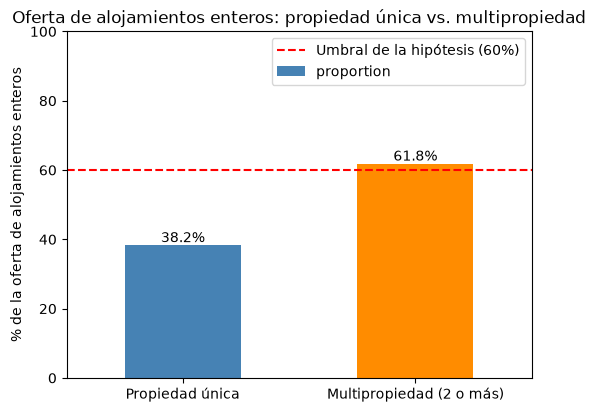

In [27]:
import matplotlib.pyplot as plt

# % de publicaciones según si el anfitrión es multipropiedad
pct = ent["multi"].value_counts(normalize=True).mul(100).reindex([False, True])
pct.index = ["Propiedad única", "Multipropiedad (2 o más)"]

print(pct.round(1))

plt.figure(figsize=(6, 4.5))
ax = pct.plot(kind="bar", color=["steelblue", "darkorange"])
ax.bar_label(ax.containers[0], fmt="%.1f%%")
ax.axhline(60, color="red", linestyle="--", label="Umbral de la hipótesis (60%)")
plt.ylim(0, 100)
plt.xticks(rotation=0)
plt.ylabel("% de la oferta de alojamientos enteros")
plt.title("Oferta de alojamientos enteros: propiedad única vs. multipropiedad")
plt.legend()
plt.show()

In [28]:
from scipy.stats import shapiro

col = "calculated_host_listings_count_entire_homes"
muestra = ent[col]

stat, p = shapiro(muestra)
print(f"Shapiro-Wilk ({col}): W={stat:.3f}, p-valor={p:.3g}")

Shapiro-Wilk (calculated_host_listings_count_entire_homes): W=0.474, p-valor=8.74e-126


d:\Proyectos\Trabajo Fundamentos\TPE_CienciaDeDatos\Azucar\Lib\site-packages\scipy\stats\_axis_nan_policy.py:601: UserWarning: scipy.stats.shapiro: For N > 5000, computed p-value may not be accurate. Current N is 26790.
  res = hypotest_fun_out(*samples, **kwds)


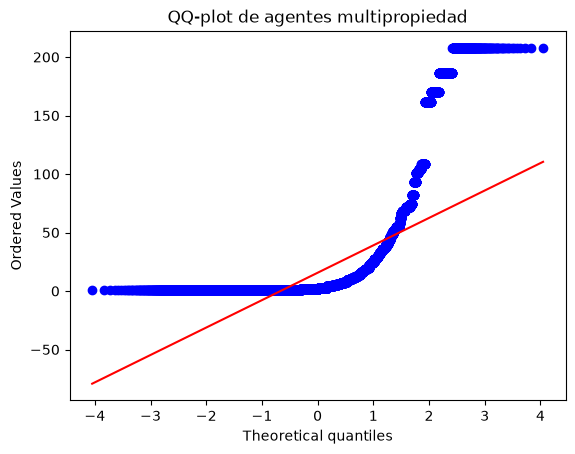

In [29]:
import scipy.stats as st
import matplotlib.pyplot as plt

st.probplot(ent[col], dist="norm", plot=plt)
plt.title("QQ-plot de agentes multipropiedad")
plt.show()

Hipotesis: A igual capacidad de huéspedes, un alojamiento se alquila más caro si garantiza mayor independencia: tener una cama para cada persona, mayor cantidad de baños por huésped, y reserva automática.

In [30]:
import numpy as np, pandas as pd

n0 = len(preprocessed_dataset)

#Transformacion de la columna bathrooms_text
t = preprocessed_dataset["bathrooms_text"].astype(str).str.lower()

n = t.str.extract(r"(\d+(?:\.\d+)?)")[0].astype(float)   #nos quedamos con el numero que aparece en el string
es_medio = t.str.contains("half")                          #contamos medio si encontramos la palabra half

#transformamos el es_medio a cantidad de baños que representa
preprocessed_dataset["banos_txt"] = np.where(es_medio, 0.5 * n.fillna(1), n)

#completamos bathrooms con los datos de bathrooms_text
preprocessed_dataset["bathrooms_ok"] = preprocessed_dataset["bathrooms"].fillna(preprocessed_dataset["banos_txt"])

#Eliminamos baños que siguieron siendo nulos despues de la transformacion
preprocessed_dataset = preprocessed_dataset.dropna(subset=["bathrooms_ok"])
n1 = len(preprocessed_dataset)

#sacamos filas con baños=0
preprocessed_dataset = preprocessed_dataset[preprocessed_dataset["bathrooms_ok"] > 0]
n2 = len(preprocessed_dataset)

print("Eliminados por baños nulos:", n0 - n1)
print("Eliminados por 0 baños:", n1 - n2)
print("Nulos en bathrooms_ok:", preprocessed_dataset["bathrooms_ok"].isna().sum())

Eliminados por baños nulos: 20
Eliminados por 0 baños: 130
Nulos en bathrooms_ok: 0


In [31]:
# Queremos saber que coincidencia habia entre ambas variables, asi sabemos si preservamos valores reales
ambas = preprocessed_dataset["bathrooms"].notna() & preprocessed_dataset["banos_txt"].notna()
print("Coinciden:", (preprocessed_dataset.loc[ambas, "bathrooms"] == preprocessed_dataset.loc[ambas, "banos_txt"]).mean())
print(preprocessed_dataset.loc[ambas & (preprocessed_dataset["bathrooms"] != preprocessed_dataset["banos_txt"]),
            ["bathrooms", "bathrooms_text", "banos_txt"]].head(10))


Coinciden: 0.999847549355896
       bathrooms bathrooms_text  banos_txt
8589         1.0      1.5 baths        1.5
10237        1.5      2.5 baths        2.5
19202        1.0        0 baths        0.0
19295        1.0        0 baths        0.0


In [32]:
#Eliminamos nulos en beds
n0 = len(preprocessed_dataset)

preprocessed_dataset = preprocessed_dataset.dropna(subset=["beds"])

print("Eliminados por beds nulos:", n0 - len(preprocessed_dataset))
print("Nulos en beds:", preprocessed_dataset["beds"].isna().sum())

Eliminados por beds nulos: 2562
Nulos en beds: 0


In [33]:
preprocessed_dataset['beds'].value_counts()

beds
1.0     13755
2.0      6884
3.0      3683
4.0      1529
5.0       510
6.0       271
7.0        91
8.0        68
10.0       36
9.0        34
12.0       29
11.0       14
14.0       12
16.0       10
15.0        9
13.0        6
22.0        5
20.0        3
25.0        3
18.0        2
21.0        2
17.0        2
32.0        2
28.0        2
30.0        2
50.0        1
24.0        1
35.0        1
23.0        1
27.0        1
38.0        1
31.0        1
40.0        1
26.0        1
Name: count, dtype: int64

In [34]:
preprocessed_dataset["beds_per_guest"] = preprocessed_dataset["beds"] / preprocessed_dataset["accommodates"]
preprocessed_dataset["baths_per_guest"] = preprocessed_dataset["bathrooms_ok"] / preprocessed_dataset["accommodates"]

In [35]:
print(preprocessed_dataset["price"].describe())
print(preprocessed_dataset["price"].quantile([.5, .9, .99, .999, 1]))
print(preprocessed_dataset.nlargest(10, "price")[["price", "accommodates", "beds", "bathrooms_ok"]])

count    2.697300e+04
mean     2.764857e+05
std      3.634269e+06
min      1.215500e+03
25%      7.620500e+04
50%      1.019893e+05
75%      1.402335e+05
max      1.716438e+08
Name: price, dtype: float64
0.500    1.019893e+05
0.900    2.149068e+05
0.990    8.076998e+05
0.999    7.629301e+07
1.000    1.716438e+08
Name: price, dtype: float64
             price  accommodates  beds  bathrooms_ok
22904  171643781.0             2   1.0           1.0
3326   169983305.0             1   1.0           1.0
24259  129721451.0             3   1.0           1.0
16530  128501556.0             1   1.0           1.0
717    119163498.4             2   1.0           1.0
24799  119163498.4             4   1.0           1.0
1704   118540097.0             4   4.0           1.0
25184  117971864.0             2   1.0           1.0
24034  110269755.0             3   2.0           1.0
24281  103854017.5             4   2.0           1.0


In [36]:
import numpy as np

n0 = len(preprocessed_dataset)

lo, hi = preprocessed_dataset["price"].quantile([.01, .99])
print("Rango conservado:", lo, "-", hi)
#limpiamos outliers y nos quedamos con precios que parecen logicos
preprocessed_dataset = preprocessed_dataset[preprocessed_dataset["price"].between(lo, hi)].copy()

preprocessed_dataset["baths_per_guest"] = preprocessed_dataset["bathrooms_ok"] / preprocessed_dataset["accommodates"]
preprocessed_dataset["beds_per_guest"] = preprocessed_dataset["beds"] / preprocessed_dataset["accommodates"]


print(n0, "->", len(preprocessed_dataset))
print(preprocessed_dataset["price"].describe())

Rango conservado: 25871.18 - 807699.7783999989
26973 -> 26433
count     26433.000000
mean     123634.199038
std       86382.856844
min       25880.000000
25%       76658.220000
50%      101989.330000
75%      138959.670000
max      807422.500000
Name: price, dtype: float64


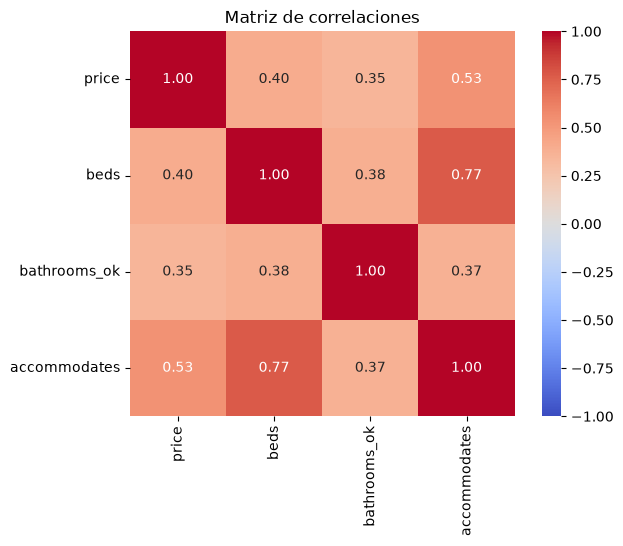

In [37]:
import seaborn as sns
import matplotlib.pyplot as plt

cols = ["price", "beds", "bathrooms_ok", "accommodates"]
corr = preprocessed_dataset[cols].corr()

plt.figure(figsize=(7, 5))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, square=True)
plt.title("Matriz de correlaciones")
plt.show()

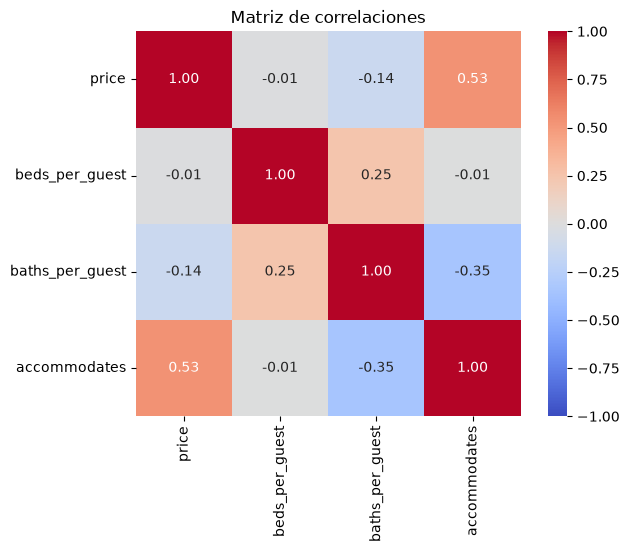

In [38]:
import seaborn as sns
import matplotlib.pyplot as plt

cols = ["price", "beds_per_guest", "baths_per_guest", "accommodates"]
corr = preprocessed_dataset[cols].corr()

plt.figure(figsize=(7, 5))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, square=True)
plt.title("Matriz de correlaciones")
plt.show()

In [39]:
import pandas as pd
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
#Variable dependiente
y = preprocessed_dataset['price']
#Variable independiente
X = preprocessed_dataset[['accommodates', 'baths_per_guest', 'beds_per_guest']]

#Estandarizacion de predictores
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)
X_scaled_df = pd.DataFrame(X_scaled, columns=X.columns, index=X.index)

ModuleNotFoundError: No module named 'sklearn'

In [ ]:
# Chequeamos que la estandarizacion haya funcionado
print("Medias y desviaciones estándar antes del escalado:")
print(pd.DataFrame(X).describe().loc[['mean', 'std']])

print("\nMedias y desviaciones estándar después del escalado:")
print(pd.DataFrame(X_scaled_df).describe().loc[['mean', 'std']])

In [ ]:
# Agregamos una constante como característica, para estimar la ordenada al origen
import statsmodels.api as sm
X_scaled_df_ = sm.add_constant(X_scaled_df)
# Ajustamos el modelo
model = sm.OLS(y, X_scaled_df_).fit()
# Imprimimos el resumen de los resultados
print(model.summary())

                            OLS Regression Results                            
Dep. Variable:                  price   R-squared:                       0.286
Model:                            OLS   Adj. R-squared:                  0.286
Method:                 Least Squares   F-statistic:                     3525.
Date:                Tue, 10 Nov 2026   Prob (F-statistic):               0.00
Time:                        20:29:31   Log-Likelihood:            -3.3351e+05
No. Observations:               26433   AIC:                         6.670e+05
Df Residuals:                   26429   BIC:                         6.671e+05
Df Model:                           3                                         
Covariance Type:            nonrobust                                         
                      coef    std err          t      P>|t|      [0.025      0.975]
-----------------------------------------------------------------------------------
const            1.236e+05    449.050    2

In [ ]:
model.resid

0        -37163.253440
1        -20520.794521
3         -8767.338177
7         -6494.112861
8        244920.904530
             ...      
29629    -37887.569125
29630     -5388.735507
29631    -37004.543440
29632     48719.614530
29633   -118275.645100
Length: 26433, dtype: float64

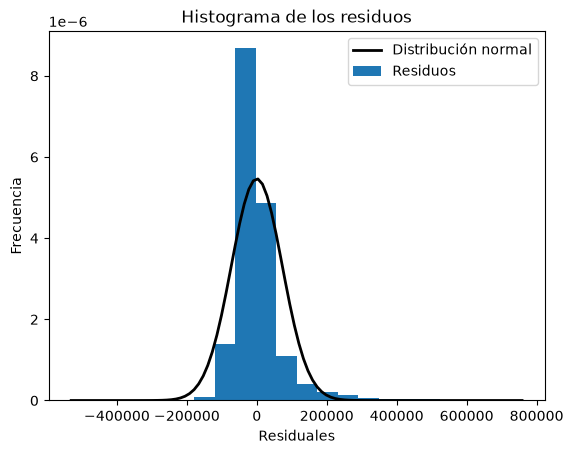

In [ ]:
import matplotlib.pyplot as plt
import statsmodels.api as sm

from scipy.stats import norm

# Histograma de residuos
plt.hist(model.resid, bins=20, density=True)
# Ajustamos una curva normal a esos residuos
mu, std = norm.fit(model.resid)
# Graficamos la curva de la distribución normal
xmin, xmax = plt.xlim()
x = np.linspace(xmin, xmax, 100)
p = norm.pdf(x, mu, std)
plt.plot(x, p, 'k', linewidth=2)

plt.xlabel("Residuales")
plt.ylabel("Frecuencia")
plt.title("Histograma de los residuos")
plt.legend(["Distribución normal", "Residuos"])
plt.show()


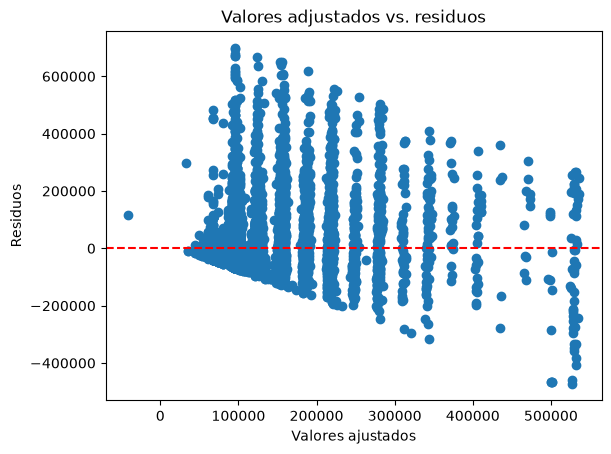

In [ ]:
plt.scatter(model.fittedvalues, model.resid)
plt.xlabel("Valores ajustados")
plt.ylabel("Residuos")
plt.title("Valores adjustados vs. residuos")
plt.axhline(0, color='red', linestyle='--')
plt.show()